# Day 3 — Concepts: geometry, life cycle, aspect

Yesterday's agents each own a belief on the shared graph. Today we follow one belief through its
life, look at what it stands on, and ask how the robot knows a thing it has seen before.

**Life cycle: how a belief begins and ends.**
- **A. Birth.** An object is born by comparing two worlds in nats, not by counting detections.
- **B. Absence.** A miss removes an object only where the object would have been seen.
- **C. Forgetting.** Replace a constant process noise by an inferred volatility.

**Geometry: what a belief stands on.**
- **D. The room.** Find the room's walls in a scan, with no labels and no map.
- **E. The pose.** Drive, and keep a calibrated belief about where you are.
- **F. Symmetry.** Find the place where gradient descent cannot help.
- **G. The common-mode ceiling.** See how little a thousand points teach when they share one error.

The thesis calls D the **acquisition** regime, where the room is a variable, and E the
**operating** regime, where the room is a constant. Part H says why the split matters.

**Aspect: a second sight.**
- **I.** Is this the chair I saw, or a new one? Position against appearance.

About two hours. Parts A to C, D to G and I are independent of each other; if time runs short, do
A, B, E, G and I.

In [1]:
import sys
from pathlib import Path

LABS = Path.cwd() if (Path.cwd() / "toyworld").exists() else Path.cwd().parent
sys.path.insert(0, str(LABS))

import matplotlib.pyplot as plt
import numpy as np

from toyworld import Gaussian, Lidar, Robot, draw, laplace, se2, two_room_apartment
from toyworld.geometry import distance_to_polygon, polygon_area, polygon_iou
from toyworld.robot import Body, predict

rng = np.random.default_rng(0)
world = two_room_apartment()
lidar = Lidar(n_beams=360, sigma=0.02, max_range=12.0)
SIGMA = 0.02

## A. Birth: a belief begins as a model comparison

A run of detections has appeared near the bottle. Does the room contain a new object, or is this
clutter? A tracker would count: *three detections close together, and the object exists*. The
generative model asks a different question: which of two worlds, one with this object and one
without it, explains these detections in fewer nats?

- **Without it**, each detection is clutter, uniform over the room: $p(z) = 1/A$.
- **With it**, each detection scatters about an unknown centre, $z_t\sim\mathcal N(\theta,\sigma_t^2 I)$,
  and $\theta$ has a broad prior over the room.

Both worlds also carry a prior probability of the object existing, $\pi$. Then

$$\Delta F = F_\text{with} - F_\text{without}, \qquad F_\text{with} =
  -\ln\pi + F_\text{Laplace}, \qquad F_\text{without} = -\ln(1-\pi) + n\ln A,$$

and the object is warranted when $\Delta F<0$. Note that each detection carries its **own** $\sigma_t$:
a detector reports how far it should be trusted, and the comparison reads that.

**Exercise 1.** Write `delta_F`, using Day 1's `laplace` for $F_\text{Laplace}$.

In [2]:
AREA, P_EXIST = 24.0, 0.1                                     # the living room's area; prior that a new object is here
CLASS_PRIOR = Gaussian([3.0, 2.0], np.diag([3.0 ** 2, 2.0 ** 2]))  # "somewhere in this room"
THETA = np.array([4.6, 0.9])


def detection_residual(z):
    return lambda th: (z - th).ravel()


def detection_jacobian(z):
    return lambda th: -np.tile(np.eye(2), (len(z), 1))


def delta_F(z, sigma):
    """F(world with the object) - F(world without it), for detections z (n, 2) with sd sigma."""
    s = np.repeat(np.broadcast_to(sigma, (len(z),)), 2)         # one sd per residual
    fit = laplace(detection_residual(z), z.mean(axis=0), s, prior=CLASS_PRIOR, jacobian=detection_jacobian(z))
    F_with = fit.free_energy - np.log(P_EXIST)
    F_without = len(z) * np.log(AREA) - np.log(1 - P_EXIST)
    return F_with - F_without


SOURCES = {                                       # what generates the detections, and the sd the detector reports
    "sharp views":   (lambda r, n: THETA + 0.05 * r.standard_normal((n, 2)), 0.05),
    "distant views": (lambda r, n: THETA + 0.30 * r.standard_normal((n, 2)), 0.30),
    "reflections":   (lambda r, n: THETA + r.uniform(-0.6, 0.6, (n, 2)), 0.10),
}
r_a = np.random.default_rng(1)
traces = {}
for name, (gen, sd) in SOURCES.items():
    z = gen(r_a, 10)
    traces[name] = [delta_F(z[:k], sd) for k in range(1, 11)]
    print(f"{name:14s} dF after 1..10 detections: " + " ".join(f"{d:6.1f}" for d in traces[name]))

sharp views    dF after 1..10 detections:    2.9   -2.6   -9.2  -15.7  -22.8  -29.9  -36.6  -43.6  -50.6  -57.5
distant views  dF after 1..10 detections:    3.0    0.7    2.8   -0.6   -3.8   -4.7   -5.6   -8.8  -11.0  -14.6
reflections    dF after 1..10 detections:    3.0   12.5    9.1   19.4   18.1   21.6   22.7   50.0   57.2   57.8


**Exercise 2.** The streak rule says: a detection *feeds* the candidate when it falls within 0.6 m
of the candidate's running mean, and the object is born once three detections have fed it. Over
300 runs, compute how often each rule accepts:
- two sharp views of a real object ($n=2$);
- ten reflections scattered over a 1.2 m patch ($n=10$).

Take the $\Delta F$ decision on all the detections of the run.

In [3]:
def streak_length(z, gate=0.6):
    fed = [z[0]]
    for p in z[1:]:
        if np.linalg.norm(p - np.mean(fed, axis=0)) < gate:
            fed.append(p)
    return len(fed)


birth_rates = {}
for name, n in (("sharp views", 2), ("reflections", 10)):
    gen, sd = SOURCES[name]
    runs = [gen(np.random.default_rng(seed), n) for seed in range(300)]
    streak = np.mean([streak_length(z) >= 3 for z in runs])
    model = np.mean([delta_F(z, sd) < 0 for z in runs])
    birth_rates[name] = (streak, model)
    print(f"{name:14s} n={n:2d}:  streak of 3 accepts {streak:5.1%}   dF<0 accepts {model:5.1%}")

sharp views    n= 2:  streak of 3 accepts  0.0%   dF<0 accepts 98.0%
reflections    n=10:  streak of 3 accepts 93.7%   dF<0 accepts  0.0%


**Questions.**
- Change the class prior to one centred on the bottle with a 10 cm spread. What happens to the number
  of detections needed, and which term of $F$ changed?
- The streak is compared against a *number of frames*; $\Delta F$ is in nats. Name one decision that
  can be traded against $\Delta F$ and cannot be traded against a streak.

*Answers.*
- The complexity term: squeezing a broad prior down to a posterior costs nats, and a tight prior has
  little squeezing left to pay for, so one detection can be enough. A strong prior makes an object
  cheap to believe in, which is exactly what a class prior is for.
- Anything else in nats: the existence log-odds that will later decide its removal, a merge of two
  instances, the expected free energy of going to look. The thesis's deployed tracker still uses a
  weighted streak, and says plainly that this is a threshold that should not be one
  (agents_life_cycle.tex, "What the surrogate costs").

## B. Absence: a miss is evidence only where the object would have been seen

Every belief carries one number for whether it exists: a log-odds $L$. A frame can say one of three
things about it:

| observation | verdict |
|---|---|
| a return inside the believed volume | **confirms** |
| predicted visible, and nothing there | **removes** |
| occluded, out of view, or too far to tell | **holds** |

The robot below tours the living room with a camera-like sensor (90° field of view) whose detector
fires on a beam landing on an object with probability $p_b(r) = e^{-(r/3\,\text{m})^2}$. It holds five
beliefs: a **table**, a small **bottle** and a **plant** tucked behind the table, all really there; a
**chair** that is really there but in the next room; and a **vase** that somebody took away before
the tour began.

**Exercise 3.** Write `predicted_beams`: which beams would land on this belief first, given the
other believed objects and, when `use_walls` is true, the walls? (`raycast` returns, for each beam,
the index of the first thing hit; indices past `len(segs)` are the discs, in order.)

In [4]:
from toyworld.lidar import raycast  # noqa: E402
from toyworld.world import Thing  # noqa: E402


class Believed:
    def __init__(self, name, centre, radius):
        self.name, self.centre, self.radius = name, np.array(centre, float), radius


world_b = two_room_apartment()
world_b.things.append(Thing("plant", "disc", [0.9, 3.3, 0.0], (0.15,)))
ALL_SEGS, SEG_LABELS = world_b.segments()
WALLS = ALL_SEGS[SEG_LABELS == "wall"]
BELIEFS = [Believed("table", [2.2, 2.6], 0.6), Believed("bottle", [4.6, 0.9], 0.08), Believed("plant", [0.9, 3.3], 0.2),
           Believed("chair", [8.4, 3.6], 0.3), Believed("vase", [5.0, 3.3], 0.15)]
camera = Lidar(n_beams=120, fov=np.deg2rad(90), sigma=0.02, max_range=8.0)
waypoints = np.array([[1.2, 0.8], [4.8, 0.8], [5.2, 2.0], [4.2, 3.4], [3.6, 1.4], [1.2, 1.2]])
TOUR = []
for i in range(240):                                    # slide along the waypoints while the head sweeps round
    s = i / 240 * (len(waypoints) - 1)
    k = int(s)
    p = waypoints[k] + (s - k) * (waypoints[k + 1] - waypoints[k])
    TOUR.append(np.array([p[0], p[1], 0.11 * i]))


def predicted_beams(b, pose, beliefs, use_walls=True):
    """Boolean (B,): the beams that would land on belief b before anything else. Also returns the ranges."""
    angles = pose[2] + camera.angles()
    dirs = np.stack([np.cos(angles), np.sin(angles)], axis=1)
    centres = np.array([x.centre for x in beliefs])
    radii = np.array([x.radius for x in beliefs])
    segs = WALLS if use_walls else np.zeros((0, 2, 2))
    d, idx = raycast(pose[:2], dirs, segs, centres, radii)
    on_b = (idx == len(segs) + beliefs.index(b)) & (d <= camera.max_range)
    return on_b, d

Now the update. How far a miss should count is $P(\text{detect}\mid\text{present})$, the probability that
the sensor would have fired had the object been there,

$$ P(\text{detect}) = 1-\prod_{\text{beams}}\big(1-p_b(r)\big). $$

One frame's evidence **saturates**: no single frame may move $L$ by more than `LOCC`, because the
points of one frame are not independent. The question that matters is on which side of that ceiling
the weight goes.

**Exercise 4.** Write `existence_step` for the three verdicts. In the correct rule the absence
increment is $-P(\text{detect})\cdot\min(c\,n_\text{pred},\ell_\text{occ})$: saturate first, weight
afterwards. With `weight_count=True`, apply the weight to the count instead, before the ceiling.

a 2%-resolvable view: saturate then weight drops L by 0.0079; weight the count drops it by 0.4000



evidence           removed: vase (frame 68)


no walls           removed: vase (frame 68), chair (frame 174)


weight the count   removed: vase (frame 13)
miss counter       removed: vase (frame 14), bottle (frame 22), chair (frame 24), plant (frame 32), table (frame 44)


Text(0.5, 1.0, 'the evidence rule')

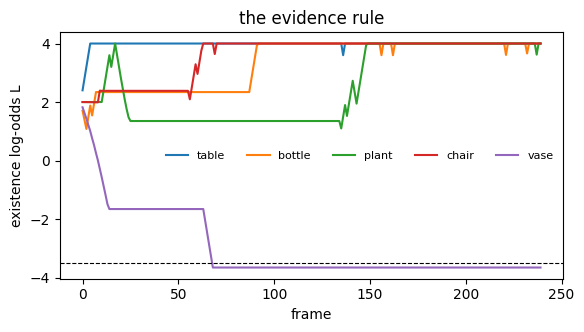

In [5]:
LOCC, PER_BEAM, L0, LMAX, L_DEAD = 0.4, 1.0, 2.0, 4.0, -3.5
R_SEE = 3.0


def p_beam(r):
    return np.exp(-(r / R_SEE) ** 2)


def existence_step(L, n_hit, on_b, ranges, weight_count=False):
    n_pred = int(on_b.sum())
    if n_hit > 0:
        return min(L + min(PER_BEAM * n_hit, LOCC), LMAX)
    if n_pred == 0:
        return L
    p_detect = 1.0 - np.prod(1.0 - p_beam(ranges[on_b]))
    if weight_count:
        drop = min(p_detect * PER_BEAM * n_pred, LOCC)
    else:
        drop = p_detect * min(PER_BEAM * n_pred, LOCC)
    return max(L - drop, -LMAX)


def run_tour(rule, seed=0):
    """rule: 'evidence', 'no walls', 'weight the count' or 'miss counter'. Returns L traces and deaths."""
    r = np.random.default_rng(seed)
    L = {b.name: L0 for b in BELIEFS}
    silent = {b.name: 0 for b in BELIEFS}
    dead, trace = {}, []
    for t, pose in enumerate(TOUR):
        scan = camera.scan(world_b, pose, r)
        h = scan.hit & (scan.labels != "wall")
        pts = se2.transform_points(pose, np.stack([scan.ranges[h] * np.cos(scan.angles[h]),
                                                   scan.ranges[h] * np.sin(scan.angles[h])], axis=1))
        pts = pts[r.random(len(pts)) < p_beam(scan.ranges[h])]    # the detector misses far objects
        alive = [b for b in BELIEFS if b.name not in dead]
        for b in alive:
            n_hit = int((np.linalg.norm(pts - b.centre, axis=1) < b.radius + 0.25).sum()) if len(pts) else 0
            on_b, d = predicted_beams(b, pose, alive, use_walls=rule != "no walls")
            if rule == "miss counter":
                silent[b.name] = 0 if n_hit else silent[b.name] + 1
                if silent[b.name] >= 15:
                    dead[b.name] = t
                continue
            L[b.name] = existence_step(L[b.name], n_hit, on_b, d, weight_count=rule == "weight the count")
            if L[b.name] <= L_DEAD:
                dead[b.name] = t
        trace.append(dict(L))
    return trace, dead


# one frame, one object: a large object 40 beams wide, each beam only 0.05% likely to fire
on_far, ranges_far = np.ones(40, bool), np.full(40, 3.0 * np.sqrt(-np.log(0.0005)))
p_far = 1 - np.prod(1 - p_beam(ranges_far))
drop_right = L0 - existence_step(L0, 0, on_far, ranges_far)
drop_count = L0 - existence_step(L0, 0, on_far, ranges_far, weight_count=True)
print(f"a {p_far:.0%}-resolvable view: saturate then weight drops L by {drop_right:.4f}; "
      f"weight the count drops it by {drop_count:.4f}\n")

tour_results = {}
for rule in ("evidence", "no walls", "weight the count", "miss counter"):
    trace, dead = run_tour(rule)
    tour_results[rule] = (trace, dead)
    print(f"{rule:18s} removed: " + (", ".join(f"{n} (frame {t})" for n, t in dead.items()) or "nothing"))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for b in BELIEFS:
    ax.plot([s[b.name] for s in tour_results["evidence"][0]], label=b.name)
ax.axhline(L_DEAD, color="k", lw=0.8, ls="--"); ax.set_xlabel("frame"); ax.set_ylabel("existence log-odds L")
ax.legend(ncol=5, frameon=False, fontsize=8); ax.set_title("the evidence rule")

**Questions.**
- Compare the rules. Which objects does each remove, and why? The rule that weights the count removes
  the right object: what is wrong with it? (Look at the frame numbers and the one-frame line above.)
- The correct rule never removes an object that can never be probed. A constant decay added under
  $P(\text{detect})$ would. Why does the thesis forbid that, and what does it do instead?

*Answers.*
- **Miss counter:** it deletes everything the head has not looked at for 15 frames; it runs on the
  agent's clock. **No walls:** the chair projects into view through the wall, finds no detection,
  and votes for its own removal: the bug the thesis's agents suffered three times. **Weighting the
  count:** it happens to reach the right verdict here, five times sooner, because a far view
  counts as fully as a near one. A 2%-resolvable view with many beams still reaches the ceiling: the
  weight has changed nothing. Only a weight applied after the ceiling can act.
- A decay is removal without evidence, on the agent's clock. The contract routes an unresolvable
  instance to a *verification pull*: it raises the expected information of a view of it, the robot
  goes to look, and the existence belief decides on evidence obtained for the purpose. Uncertainty you
  cannot resolve from here is a reason to move, not a reason to forget.

## C. Forgetting: how fast does *this* object change?

A static object is usually tracked by adding a constant process noise every frame,
$\Sigma \leftarrow \Sigma + Q$, whether or not anything was seen. That makes two predictions, neither
of which depends on how long the object has been known:

- **unobserved**, the variance grows linearly: $\Sigma(n)=\Sigma_0+Qn$;
- **observed**, precision does not accumulate: it stops at a floor $\sigma_\text{steady}\approx(Q/i)^{1/4}$,
  where $i$ is the information of one frame.

The cure replaces the constant by an inferred, per-object quantity $Q = e^{\zeta}$, driven by how
surprised the belief is. With innovation $\nu$ and its predicted variance $S$, the normalised surprise is
$d = \nu^2/S$, and

$$\zeta \leftarrow \zeta + \eta\Big(\tfrac12\big(\tilde d - \mathbb E[\tilde d\,]\big)
   - \frac{\zeta-\zeta_0}{\sigma_\zeta^2}\Big),\qquad
   \tilde d = \frac{(\nu_0+1)\,d}{\nu_0+d}. $$

The first term compares the surprise actually seen with the surprise a calibrated model expects. The
last is the hyperprior's pull-back, which keeps $\zeta$ recoverable. $\tilde d$ is the surprise of
a Student-$t$ innovation: it saturates, so that **one outrageous frame moves $\zeta$ by a bounded
amount**, and only a *run* of surprises moves it far.

The stream below is one coordinate of a table: 400 s at 10 Hz, one spurious mask 40 cm off at frame
4000, unobserved from frame 5000 to 5600, genuinely moved 50 cm at frame 6000.

**Exercise 5.** Fill in the Kalman step and the $\zeta$ update.

E[d~] under a calibrated model = 0.786
predicted floor (Q/i)^(1/4) = 10.0 mm
constant Q  sd before the spurious mask   9.4 mm | moved by it  92.4 mm, 10 frames on  16.9 mm | sd after the 60 s gap 122.8 mm | adapts to the real move in 9 frames
inferred Q  sd before the spurious mask   6.5 mm | moved by it  44.0 mm, 10 frames on  19.2 mm | sd after the 60 s gap  45.4 mm | adapts to the real move in 15 frames


Text(0.5, 0, 'frame')

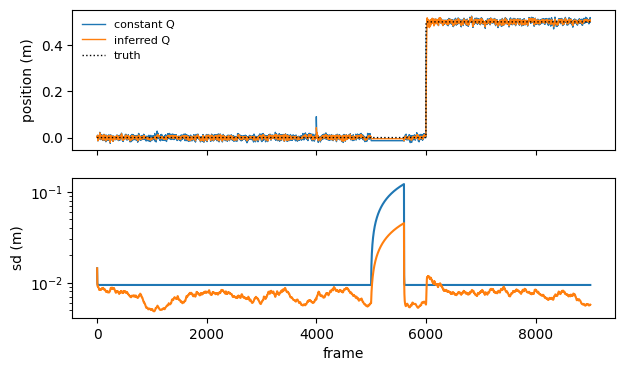

In [6]:
T_FRAMES = 9000
R_FRAME = 0.02 ** 2
Q_CONST = 2.5e-5                                    # (0.005 m)^2 per frame, the deployed process noise
ZETA0, SIGMA_ZETA, ETA, NU0 = np.log(Q_CONST), 10.0, 0.1, 4.0
_d = np.linspace(1e-6, 60, 600000)
_chi2 = np.exp(-_d / 2) / np.sqrt(2 * np.pi * _d)
E_DTILDE = np.sum((NU0 + 1) * _d / (NU0 + _d) * _chi2) * (_d[1] - _d[0])
print(f"E[d~] under a calibrated model = {E_DTILDE:.3f}")

r_c = np.random.default_rng(0)
true_c = np.zeros(T_FRAMES); true_c[6000:] = 0.5
z_c = true_c + np.sqrt(R_FRAME) * r_c.standard_normal(T_FRAMES); z_c[4000] += 0.4
seen = np.ones(T_FRAMES, bool); seen[5000:5600] = False


def track(z, seen, infer):
    """Run the filter. infer=False: constant Q. Returns arrays mu, Sigma, zeta."""
    mu, Sig, zeta = z[0], R_FRAME, ZETA0
    out = []
    for t in range(len(z)):
        Q = Q_CONST if not infer else np.exp(zeta)
        P = Sig + Q
        if seen[t]:
            S = P + R_FRAME
            nu = z[t] - mu
            K = P / S
            mu, Sig = mu + K * nu, (1 - K) * P
            if infer:
                d = nu ** 2 / S
                d_tilde = (NU0 + 1) * d / (NU0 + d)
                zeta += ETA * (0.5 * (d_tilde - E_DTILDE) - (zeta - ZETA0) / SIGMA_ZETA ** 2)
        else:
            Sig = P
        out.append((mu, Sig, zeta))
    return np.array(out).T


mu_q, S_q, _ = track(z_c, seen, infer=False)
mu_v, S_v, zeta_v = track(z_c, seen, infer=True)


def adapt_time(mu):
    return int(np.argmax(np.abs(mu[6000:] - 0.5) < 0.05))


print(f"predicted floor (Q/i)^(1/4) = {(Q_CONST * R_FRAME) ** 0.25 * 1000:.1f} mm")
for name, mu, Sig in (("constant Q", mu_q, S_q), ("inferred Q", mu_v, S_v)):
    print(f"{name:11s} sd before the spurious mask {np.sqrt(Sig[3999]) * 1000:5.1f} mm | "
          f"moved by it {abs(mu[4000] - mu[3999]) * 1000:5.1f} mm, 10 frames on {abs(mu[4010] - mu[3999]) * 1000:5.1f} mm | "
          f"sd after the 60 s gap {np.sqrt(Sig[5599]) * 1000:5.1f} mm | adapts to the real move in {adapt_time(mu)} frames")

fig, axes = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
axes[0].plot(mu_q, label="constant Q", lw=1); axes[0].plot(mu_v, label="inferred Q", lw=1); axes[0].plot(true_c, "k:", lw=1, label="truth")
axes[0].legend(frameon=False, fontsize=8); axes[0].set_ylabel("position (m)")
axes[1].semilogy(np.sqrt(S_q), label="constant Q"); axes[1].semilogy(np.sqrt(S_v), label="inferred Q"); axes[1].set_ylabel("sd (m)"); axes[1].set_xlabel("frame")

**Exercise 6.** Feed `track` a stream with a constant **bias**: every frame reads 5 cm high, from the
start, with the same noise. Report the final error and the final standard deviation of both filters,
and their ratio. What has the inferred volatility done?

In [7]:
z_bias = 0.05 + np.sqrt(R_FRAME) * np.random.default_rng(2).standard_normal(T_FRAMES)
for name, infer in (("constant Q", False), ("inferred Q", True)):
    mu, Sig, _ = track(z_bias, np.ones(T_FRAMES, bool), infer)
    err = np.abs(mu[-2000:]).mean()
    print(f"{name:11s} mean error {err * 1000:5.1f} mm, claimed sd {np.sqrt(Sig[-2000:].mean()) * 1000:5.2f} mm: "
          f"{err / np.sqrt(Sig[-2000:].mean()):.1f} sigma out")

constant Q  mean error  50.8 mm, claimed sd  9.40 mm: 5.4 sigma out
inferred Q  mean error  50.9 mm, claimed sd  6.67 mm: 7.6 sigma out


*Answer.* A bias is perfectly consistent, so the surprise stays small and nothing raises $\zeta$:
both filters report a few millimetres of uncertainty while being wrong by the whole 5 cm, and the
inferred one is, if anything, more confident. The volatility cannot see a bias; only an error model can. That is why the thesis says volatility
and the common-mode $\Sigma_\delta$ must be reasoned about together, and it is the same reason a shared
bias, unlike a symmetric error, must be gated rather than down-weighted.

## D. The first belief born: acquiring the room

The room is a belief with a birth of its own: nothing in the first scan says how many walls there
are. Yesterday the robot was told which points belonged to the wall, and knew its pose; here it
knows neither.

### D1. Whose frame?

The robot has no map, so there is no "world" frame it could report a pose in. The only frame
available is its own frame at the moment it starts. That choice is a **gauge**: a convention
that no measurement could ever fix, because the data would be identical in any other frame.
From here on, the **map frame is the robot's frame at t = 0**. The true starting pose `TRUE0`
is used only for grading.

Text(0.5, 1.0, 'what the robot has: one scan, in its own frame')

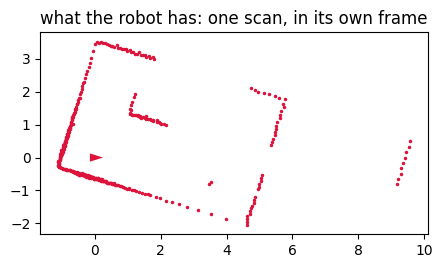

In [8]:
TRUE0 = np.array([1.0, 0.6, 0.3])       # ground truth, for grading only
scan0 = lidar.scan(world, TRUE0, rng)
P0 = scan0.points()                      # robot frame at t=0  ==  map frame

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(P0[:, 0], P0[:, 1], ".", ms=3, color="crimson")
draw.robot([0, 0, 0], ax)
ax.set_aspect("equal"); ax.set_title("what the robot has: one scan, in its own frame")

### D2. Which way is the room?

Rooms are mostly rectilinear. Each scan point has a local surface normal, which you can estimate
from its neighbours. If the room has a dominant direction $\theta_0$, every normal is
$\theta_0 + k\pi/2$ for some $k$. Multiplying the angle by 4 maps all four of those onto the same
angle, $4\theta_0$, so a **circular mean of $4\varphi_i$** votes for the room's direction without
knowing which wall each point is on.

**Exercise 7.** Compute $\theta_0 = \tfrac14 \arg \sum_i e^{4 i \varphi_i}$ from the normals
provided.

In [9]:
def scan_normals(P, max_gap=0.3):
    """Normal angle at each point, from its angular neighbours. `ok` is False across depth jumps."""
    order = np.argsort(np.arctan2(P[:, 1], P[:, 0]))
    Q = P[order]
    tangent = np.roll(Q, -1, axis=0) - np.roll(Q, 1, axis=0)
    ok = np.linalg.norm(tangent, axis=1) < max_gap
    phi = np.arctan2(tangent[:, 1], tangent[:, 0]) + np.pi / 2
    return Q, phi, ok


Q0, phi0, ok0 = scan_normals(P0)
theta0 = np.angle(np.sum(np.exp(4j * phi0[ok0]))) / 4
print(f"theta0 = {np.degrees(theta0):.2f}°   (truth, for grading: the room axes sit at "
      f"{np.degrees(se2.wrap(-TRUE0[2])):.2f}° mod 90° in the robot frame)")

theta0 = -17.19°   (truth, for grading: the room axes sit at -17.19° mod 90° in the robot frame)


**Question.** The thesis found that this direction must be **voted over all frames**, never taken
from the first scan. Why might the first scan be a bad place to take a gauge from?

*Answer.* The first scan is one noisy, partial view. If it happens to see mostly one wall, or a
piece of oblique furniture, $\theta_0$ is biased, and every wall's Manhattan class inherits that
bias. Worse, nothing downstream can correct it: a frame is part of an estimator's *output*, so a
wrong frame makes a good fit look like a wrong shape. (A real case, work in progress: a fit with area 23.88 m²
against 24.00 true, but aspect ratio 1.344 against 1.500, was a frame error, not a fit error.)

### D3. Which points belong to a wall? A band that is derived, not chosen

A point belongs to a line when the line explains it better than clutter does. Clutter is uniform
over the scan's area $A$. A wall concentrates its points in a strip $L$ long and about $\sigma$
wide. The density ratio for a point at distance $r$ from the line is

$$ \frac{p_\text{wall}}{p_\text{clutter}} = \frac{A}{L\sqrt{2\pi}\,\sigma}\, e^{-r^2/2\sigma^2}. $$

The point is an inlier when this ratio exceeds 1, and it brings $\ln$(ratio) nats of evidence.

**Exercise 8.** Write the band half-width $r_\text{max}$ (where the ratio equals 1) and the
evidence per point, $\mathrm{gain}(r)$. Evaluate both for $A$ = the scan's bounding area,
$L = 4$ m and $\sigma = 2$ cm. Then plot $r_\text{max}$ against $L$ from 0.5 to 20 m.

A = 59.6 m²;  L = 4 m:  band = ±6.7 cm = 3.37 σ;  a point on the line brings 5.69 nats


Text(0.5, 1.0, 'a longer wall must fit each point more closely')

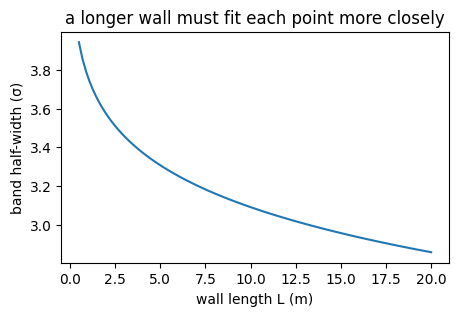

In [10]:
A_scan = np.ptp(P0[:, 0]) * np.ptp(P0[:, 1])


def band_halfwidth(A, L, sigma=SIGMA):
    return np.sqrt(2 * sigma ** 2 * np.log(A / (L * np.sqrt(2 * np.pi) * sigma)))


def gain(r, A, L, sigma=SIGMA):
    """Nats of evidence a point at distance r brings to the line (negative: clutter explains it better)."""
    return np.log(A / (L * np.sqrt(2 * np.pi) * sigma)) - r ** 2 / (2 * sigma ** 2)


print(f"A = {A_scan:.1f} m²;  L = 4 m:  band = ±{band_halfwidth(A_scan, 4.0) * 100:.1f} cm "
      f"= {band_halfwidth(A_scan, 4.0) / SIGMA:.2f} σ;  a point on the line brings {gain(0, A_scan, 4.0):.2f} nats")
Ls = np.linspace(0.5, 20, 100)
plt.figure(figsize=(5, 3))
plt.plot(Ls, band_halfwidth(A_scan, Ls) / SIGMA)
plt.xlabel("wall length L (m)"); plt.ylabel("band half-width (σ)")
plt.title("a longer wall must fit each point more closely")

The band comes out at about $3\sigma$, close to what anyone would have picked by hand. The
derivation adds two things a tuned constant cannot:
- the band **narrows as $L$ grows**, because a long wall is a more expensive explanation of any
  one point;
- each point arrives with its evidence in **nats**, the currency every structural decision will
  be priced in.

### D4. Four walls

**Exercise 9.** For each Manhattan class $k = 0..3$, with normal angle $a_k = \theta_0 + k\pi/2$:
1. initialise $d_k$ as the median of $n(a_k)^\top p$ over the points whose normal is within 15° of
   $\pm a_k$ and which lie in front of the robot ($n^\top p > 0$);
2. refine $(\alpha, d)$ with a Laplace fit in which every point is weighted by its
   **responsibility** $w = \rho/(1+\rho)$, where $\rho$ is the density ratio. A point with weight
   $w$ enters with standard deviation $\sigma/\sqrt{w}$. Re-weight and refit a few times.

In [11]:
def line_residual(P):
    return lambda th: np.cos(th[0]) * P[:, 0] + np.sin(th[0]) * P[:, 1] - th[1]


def fit_wall(P, alpha, d, A, iters=5):
    L = 4.0
    for _ in range(iters):
        r = line_residual(P)([alpha, d])
        rho = A / (L * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
        w = rho / (1 + rho)
        use = w > 1e-3
        fit = laplace(line_residual(P[use]), [alpha, d], SIGMA / np.sqrt(w[use]))
        alpha, d = fit.belief.mu
        inl = P[w > 0.5]
        along = inl @ np.array([-np.sin(alpha), np.cos(alpha)])
        L = max(np.ptp(along), 0.5) if len(inl) > 2 else L   # the wall's observed length
    return fit.belief, w


walls = []
for k in range(4):
    a = theta0 + k * np.pi / 2
    n = np.array([np.cos(a), np.sin(a)])
    proj = Q0 @ n
    same_class = ok0 & (np.abs(se2.wrap(2 * (phi0 - a))) < np.deg2rad(30)) & (proj > 0)
    d0 = np.median(proj[same_class])
    belief, w = fit_wall(Q0, a, d0, A_scan)
    walls.append(belief)
    print(f"wall {k}: alpha = {np.degrees(belief.mu[0]):8.3f}° ± {np.degrees(belief.sd[0]):.3f}°,"
          f"  d = {belief.mu[1]:.3f} ± {belief.sd[1] * 1000:.1f} mm,  inliers {int((w > 0.5).sum())}")

wall 0: alpha =  -17.170° ± 0.157°,  d = 5.001 ± 5.0 mm,  inliers 31
wall 1: alpha =   72.800° ± 0.098°,  d = 3.400 ± 3.5 mm,  inliers 39
wall 2: alpha =  162.801° ± 0.119°,  d = 0.998 ± 2.3 mm,  inliers 107
wall 3: alpha =  252.821° ± 0.093°,  d = 0.601 ± 1.8 mm,  inliers 145


**Exercise 10.** The polygon is the walls intersected in cyclic order. Build it, map it into the
world with the grading-only `TRUE0`, and compute the IoU against the true living room.

IoU = 0.9939,  area 23.991 m² (truth 24)


Text(0.5, 1.0, 'the room, from one scan, in the map frame')

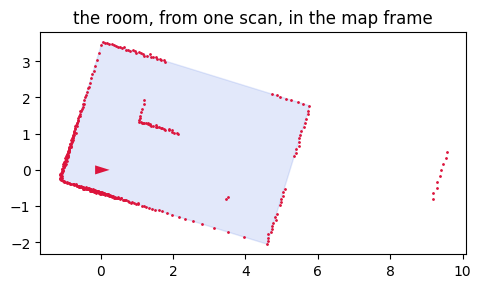

In [12]:
def intersect(w1, w2):
    A = np.array([[np.cos(w1.mu[0]), np.sin(w1.mu[0])], [np.cos(w2.mu[0]), np.sin(w2.mu[0])]])
    return np.linalg.solve(A, [w1.mu[1], w2.mu[1]])


room = np.array([intersect(walls[k], walls[(k + 1) % 4]) for k in range(4)])
truth_room = world.room("living").polygon
print(f"IoU = {polygon_iou(se2.transform_points(TRUE0, room), truth_room):.4f},  area {polygon_area(room):.3f} m² (truth 24)")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(Q0[:, 0], Q0[:, 1], ".", ms=2, color="crimson")
ax.fill(*np.vstack([room, room[:1]]).T, fc="royalblue", alpha=0.15, ec="royalblue")
draw.robot([0, 0, 0], ax); ax.set_aspect("equal"); ax.set_title("the room, from one scan, in the map frame")

### D5. The price of a shape

Real rooms are not always four walls. The thesis prices every extra edge by **minimum
description length**. To transmit an edge you must say which of the four Manhattan directions it
takes ($\ln 4$ nats), and where its offset lies among $2R/c$ distinguishable positions, with $R$
the sensor range and $c$ the resolution:

$$ L_\text{edge} = \ln 4 + \ln(2R/c). $$

**Exercise 11.** Compute $L_\text{edge}$ for $R = 12$ m and $c = 5$ cm. Then compute the evidence
the **table's south face** would bring if it were proposed as a wall: the sum of `gain(r)` over the
points on it (use the true labels this once). Does the MDL price stop the table from becoming a
wall?

In [13]:
L_edge = np.log(4) + np.log(2 * 12.0 / 0.05)
table_pts = P0[scan0.labels[scan0.hit] == "table"]
face = laplace(line_residual(table_pts), [theta0 + np.pi / 2, np.median(table_pts @ [-np.sin(theta0), np.cos(theta0)])], SIGMA)
r_face = line_residual(table_pts)(face.belief.mu)
evidence = gain(r_face, A_scan, 1.2).clip(min=0).sum()
print(f"L_edge = {L_edge:.2f} nats;  the table face would earn {evidence:.0f} nats from {len(table_pts)} points")

L_edge = 7.56 nats;  the table face would earn 82 nats from 34 points


**Question.** The table face pays the MDL price many times over, so the price cannot be what
keeps furniture out of the room's outline. What evidence *does* tell a table face from a wall?

*Answer.* **Free space.** Beams pass beside and beyond the table and hit the real wall behind it,
so the region behind the "wall" is observed to be empty. A room is a region the robot can see
into, not just a set of surfaces. That is why the thesis draws the outline from a grid that
counts, per cell, the beams that pass through as well as the beams that stop, and why free floor
beyond an edge counts as evidence against that edge.

## E. Localising in the room you just built

Now the room is a constant (the operating regime) and the robot drives. Each step has two
parts:
- **Predict.** `predict(belief, odometry)` pushes the encoder and gyro noise through the motion
  Jacobian. No constant process noise is added.
- **Correct.** A Laplace fit of the scan against the room, with the prediction as the prior. The
  residual of each scan point is its distance to the nearest wall: the localiser's
  distance field.

**Exercise 12.** Write the pose residual: map the robot-frame points through a candidate pose $X$,
then take their distance to the polygon.

rms error: x 2.2 mm, y 1.0 mm, theta 0.036°


Text(0.5, 1.0, 'localising against the estimated room (ellipses ×20)')

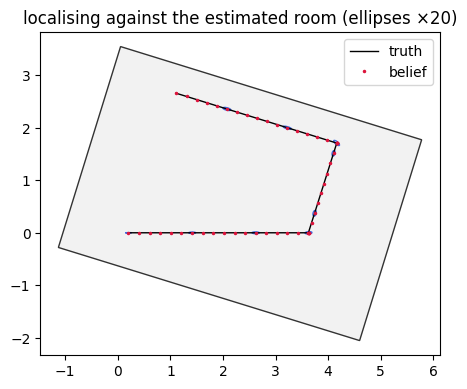

In [14]:
def pose_residual(P_robot, polygon):
    return lambda X: distance_to_polygon(se2.transform_points(X, P_robot), polygon)


def localise(prior, P_robot, polygon, iters=3):
    A, x = polygon_area(polygon), prior.mu.copy()
    for _ in range(iters):
        r = pose_residual(P_robot, polygon)(x)
        rho = A / (20.0 * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
        w = rho / (1 + rho)
        use = w > 1e-3
        fit = laplace(pose_residual(P_robot[use], polygon), x, SIGMA / np.sqrt(w[use]), prior=prior)
        x = fit.belief.mu
    return fit.belief


turn_to_north = [(0.0, (np.pi / 2 - 0.3) / 2.5)] * 5
turn_left = [(0.0, np.pi / 6)] * 6
COMMANDS = [(0.4, 0.0)] * 18 + turn_to_north + [(0.4, 0.0)] * 9 + turn_left + [(0.4, 0.0)] * 16


def drive(polygon, seed, commands=COMMANDS, scans=True):
    """Run the filter along the route. Returns the true poses (map frame) and the beliefs."""
    r = np.random.default_rng(seed)
    robot = Robot(TRUE0.copy(), Body(), r)
    belief = Gaussian([0, 0, 0], np.diag([1e-9] * 3))
    truths, beliefs = [], []
    for v, w in commands:
        belief = predict(belief, robot.step(v, w, 0.5))
        assert world.room_of(robot.pose[:2]) == "living", "the route left the room!"
        if scans:
            belief = localise(belief, lidar.scan(world, robot.pose, r).points(), polygon)
        truths.append(se2.ominus(robot.pose, TRUE0))
        beliefs.append(belief)
    return np.array(truths), beliefs


def nees(truths, beliefs):
    out = []
    for t, b in zip(truths, beliefs):
        e = t - b.mu
        e[2] = se2.wrap(e[2])
        out.append(e @ np.linalg.solve(b.Sigma, e))
    return np.array(out)


truths, beliefs = drive(room, seed=1)
err = np.array([t - b.mu for t, b in zip(truths, beliefs)])
print(f"rms error: x {np.sqrt((err[:, 0] ** 2).mean()) * 1000:.1f} mm, y {np.sqrt((err[:, 1] ** 2).mean()) * 1000:.1f} mm, "
      f"theta {np.degrees(np.sqrt((err[:, 2] ** 2).mean())):.3f}°")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.fill(*np.vstack([room, room[:1]]).T, fc="0.95", ec="0.2")
ax.plot(truths[:, 0], truths[:, 1], "k-", lw=1, label="truth")
mus = np.array([b.mu for b in beliefs])
ax.plot(mus[:, 0], mus[:, 1], ".", color="crimson", ms=3, label="belief")
for b in beliefs[::6]:
    draw.covariance(b.mu, b.Sigma * 400, ax)   # 2σ ellipses, ×20 so they are visible
ax.set_aspect("equal"); ax.legend(); ax.set_title("localising against the estimated room (ellipses ×20)")

**Is the belief honest?** The normalised estimation error squared (NEES),
$e^\top\Sigma^{-1}e$, averages to the state dimension (3) when the covariance is right. It is
larger when the belief is over-confident, and smaller when it is pessimistic.

**Exercise 13.** Compute the mean NEES over 4 seeds for three maps:
- the true polygon;
- the one-scan estimate from Part D;
- the true polygon with its east wall moved 1.5 cm.

In [15]:
true_room = se2.to_frame(TRUE0, truth_room)
bad_room = true_room.copy()
east = np.argsort(true_room @ np.array([np.cos(-0.3), np.sin(-0.3)]))[-2:]   # the two east corners
bad_room[east] += 0.015 * np.array([np.cos(-0.3), np.sin(-0.3)])
for name, poly in (("true room", true_room), ("estimated (part D)", room), ("east wall +1.5 cm", bad_room)):
    score = np.mean([nees(*drive(poly, seed)).mean() for seed in range(4)])
    print(f"{name:20s} mean NEES = {score:6.2f}   (3 = honest)")

true room            mean NEES =   1.95   (3 = honest)


estimated (part D)   mean NEES =   3.81   (3 = honest)


east wall +1.5 cm    mean NEES =  89.84   (3 = honest)


**Lesson.** A wall 1.5 cm out of place makes the localiser **confidently wrong**: its error
grows to several of its own standard deviations, and nothing inside the localiser notices. The
polygon is a *constant* in the operating regime. It contributes no uncertainty, so its errors are
shared by every scan, forever. That is the price of the regime split, and it is why the thesis
says the operating regime "cannot detect that the polygon it was given is wrong". Something
else, the acquisition regime, must be right, or know when it is not.

## F. The room's symmetry

A 6 × 4 m rectangle looks the same after a half-turn about its centre. Take the robot's final
scan and evaluate the Laplace free energy at the true pose and at its half-turn image, with a weak
prior and no odometry.

**Exercise 14.** Compute both $F$ values.

In [16]:
r_ = np.random.default_rng(7)
X_true = truths[-1]
P_last = lidar.scan(world, se2.compose(TRUE0, X_true), r_).points()
centre = true_room.mean(axis=0)
X_flip = np.array([*(2 * centre - X_true[:2]), se2.wrap(X_true[2] + np.pi)])
for name, X0 in (("true pose", X_true), ("half-turn", X_flip)):
    b = localise(Gaussian(X0, np.diag([1.0, 1.0, 1.0])), P_last, true_room)
    r = pose_residual(P_last, true_room)(b.mu)
    rho = polygon_area(true_room) / (20 * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
    w = rho / (1 + rho)
    F = laplace(pose_residual(P_last[w > 1e-3], true_room), b.mu, SIGMA / np.sqrt(w[w > 1e-3]),
                prior=Gaussian(X0, np.eye(3))).free_energy
    print(f"{name:10s} pose {np.round(b.mu, 3)}   F = {F:.2f} nats")

true pose  pose [1.11  2.657 2.84 ]   F = -786.82 nats
half-turn  pose [ 3.539 -1.164 -0.302]   F = -786.82 nats


**Questions.**
- The two free energies differ by a fraction of a nat. No gradient connects the two poses, so
  descent cannot choose between them. What must?
- The table and the door gap are *not* symmetric. Why don't they break the tie here?

*Answers.*
- The choice is **discrete**, so it needs a discrete search plus evidence the room cannot
  provide: continuity with the previous pose (the motion prior), or a landmark that is not
  symmetric. The thesis's localiser searches the room's symmetries explicitly. That is one of the
  few places where a threshold is the right design, because a continuous relaxation of a
  discrete choice is not a better model of it.
- Because the **model** does not contain them. Our polygon has no door gap, and the table's
  points are classed as clutter. Evidence the model throws away cannot break a tie. The thesis
  later uses the fridge as a room landmark for exactly this purpose.

## G. The common-mode ceiling

Before there is a room to localise against, the robot only has odometry, and its pose
uncertainty grows. Suppose it maps the **table's south face** from there, using a dense sensor
(think: a camera mask with thousands of pixels). Each point's map position is
$p_\text{map} = X \oplus p_\text{robot}$, so every point inherits the **same** pose error.

Marginalising that shared error gives the information one frame can carry:

$$ \mathcal I = J^\top(\sigma^2 I + J_X\Sigma_X J_X^\top)^{-1}J
   \;\overset{\text{Woodbury}}{\Longrightarrow}\;
   \operatorname{var}(\hat y) = \frac{\sigma^2}{N} + j^\top \Sigma_X\, j
   \;\xrightarrow[N\to\infty]{}\; j^\top\Sigma_X j \neq 0, $$

where $j = \partial y_\text{map} / \partial X$, averaged over the points.

**Exercise 15.** Over 60 runs, dead-reckon the first leg, estimate the face's offset along its normal from
$N$ = 1 … 32 points, and compare the true rms error with two predictions: independent points
only (with Day 1's per-point $\sigma_i = \sigma|u_i^\top n|$), and the Woodbury formula.

N=  1  actual   8.82 mm   independent   4.92   Woodbury   9.29
N=  2  actual   7.44 mm   independent   3.54   Woodbury   8.47
N=  4  actual   7.49 mm   independent   2.50   Woodbury   8.02
N=  8  actual   7.15 mm   independent   1.78   Woodbury   7.74
N= 16  actual   6.69 mm   independent   1.25   Woodbury   7.64
N= 32  actual   6.57 mm   independent   0.89   Woodbury   7.58


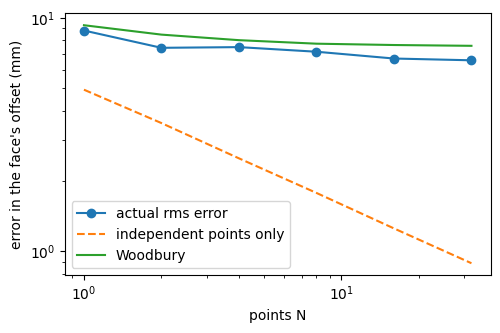

In [17]:
dense = Lidar(n_beams=2880, sigma=SIGMA)
Ns = [1, 2, 4, 8, 16, 32]
rows = {N: [] for N in Ns}
for seed in range(60):
    r_ = np.random.default_rng(seed)
    _, bs = drive(true_room, seed, COMMANDS[:18], scans=False)   # odometry only
    b = bs[-1]
    robot_pose = se2.compose(TRUE0, _[-1])
    s = dense.scan(world, robot_pose, r_)
    on_table = s.labels[s.hit] == "table"
    true_pts = np.stack([np.cos(s.angles), np.sin(s.angles)], 1)[s.hit] * s.true_ranges[s.hit, None]
    on_face = on_table & (np.abs(se2.transform_points(robot_pose, true_pts)[:, 1] - 2.2) < 1e-6)  # grading
    P_face = s.points()[on_face]
    for N in Ns:
        idx = r_.choice(len(P_face), N, replace=False)
        pts_map = se2.transform_points(b.mu, P_face[idx])
        n_face = np.array([-np.sin(-0.3), np.cos(-0.3)])             # the face's normal, map frame
        d_true = se2.to_frame(TRUE0, np.array([[2.2, 2.2]]))[0] @ n_face
        err = (pts_map @ n_face).mean() - d_true                     # what the robot would report, minus truth
        th = b.mu[2]
        dp_dth = np.stack([-np.sin(th) * P_face[idx, 0] - np.cos(th) * P_face[idx, 1],
                           np.cos(th) * P_face[idx, 0] - np.sin(th) * P_face[idx, 1]], 1)
        j = np.array([n_face[0], n_face[1], (dp_dth @ n_face).mean()])  # ∂(offset)/∂(x, y, θ)
        u = P_face[idx] / np.linalg.norm(P_face[idx], axis=1, keepdims=True)     # beam directions, robot frame
        u_map = u @ se2.rot(th).T
        sig_i = SIGMA * np.abs(u_map @ n_face)                       # Day 1: noise along the beam, seen along the normal
        var_indep = np.sum(sig_i ** 2) / N ** 2
        rows[N].append((err, np.sqrt(var_indep), np.sqrt(var_indep + j @ b.Sigma @ j)))

rms = [np.sqrt(np.mean([e ** 2 for e, _, _ in rows[N]])) for N in Ns]
naive = [np.mean([n for _, n, _ in rows[N]]) for N in Ns]
wood = [np.mean([w for _, _, w in rows[N]]) for N in Ns]
plt.figure(figsize=(5.5, 3.4))
plt.loglog(Ns, np.array(rms) * 1000, "o-", label="actual rms error")
plt.loglog(Ns, np.array(naive) * 1000, "--", label="independent points only")
plt.loglog(Ns, np.array(wood) * 1000, "-", label="Woodbury")
plt.xlabel("points N"); plt.ylabel("error in the face's offset (mm)"); plt.legend()
for N, a, n_, w_ in zip(Ns, rms, naive, wood):
    print(f"N={N:3d}  actual {a * 1000:6.2f} mm   independent {n_ * 1000:6.2f}   Woodbury {w_ * 1000:6.2f}")

**Lesson.** Past a handful of points, more pixels buy nothing: the error stops at the pose
error, not at zero. A filter that kept counting points as independent would report
under a millimetre while being off by about seven. That is the over-confidence every concept agent in
the thesis must guard against, and the reason the agents carry this term explicitly.

## H. Why the two regimes are kept apart

You have now run both regimes. A natural question is why not estimate the room and the pose
together all the time, as SLAM does. The thesis answers that a room changes over years and a pose
changes every cycle. Estimating them jointly at frame rate tracks a constant at great expense. So
the room is estimated jointly only until it is settled, and then handed over as a constant.

The thesis also keeps a loop from forming during acquisition. A wrong wall would drag the pose,
and the dragged pose would confirm the wrong wall. So the pose comes from plain scan-to-map SLAM,
which knows nothing about walls, and the outline is drawn from a map filled at that pose: the
outline depends on the pose, and never feeds back into it.
Exercise 13 is the small version of that lesson: **a factor inherits the errors of whatever it is
estimated through.**

## I. Aspect: is this the chair I saw?

The robot left a room with three chairs in it, and has come back. A chair is detected. Long-term
memory holds what it knew about the three, and the question is the same kind of question as a
birth: which of several worlds explains this detection in fewer nats? The worlds are *it is
chair 0*, *chair 1*, *chair 2*, or **it is a chair I have never met**. "New" has to be on the
list, or every detection is forced onto some remembered chair.

**Where it is.** A remembered chair either stayed where it was, or was moved and could be anywhere
in the room, with probability $\pi$. A new chair could be anywhere:

$$ p(x\mid k) = (1-\pi)\,\mathcal N(x;\mu_k, 2\sigma_p^2 I) + \frac{\pi}{A},
   \qquad p(x\mid\text{new}) = \frac1A. $$

The covariance is $2\sigma_p^2$ because both the memory and the new detection carry the position
error $\sigma_p$. This is the form the robot uses, in `common/recall_match/recall_match.h`.

**What it looks like.** A view is summarised as a vector $a$ of 16 numbers. Chairs differ: each
has its own look $m$, drawn from the class, $m\sim\mathcal N(c,\tau^2 I)$. A view of a chair
scatters around its look, $a\sim\mathcal N(m,\sigma_a^2 I)$. So the instance and the class make
different predictions, and their ratio is the evidence:

$$ r_k = \ln\mathcal N(a; m_k,\sigma_a^2 I) - \ln\mathcal N(a; c,(\tau^2+\sigma_a^2) I). $$

The score of chair $k$ is $\ln p(x\mid k) + r_k$, the score of "new" is $\ln(1/A)$, and the highest
wins. A candidate must be strictly better than "new"; a tie goes to "new". This toy is cleaner than
the robot: its look vectors are made up, and the robot's acting recall today uses **position only**.

**Exercise 16.** Write `log_location` and `decide`. **Exercise 17.** Write `log_app_ratio`.

In [18]:
ROOM_W, ROOM_H, ROOM_A = 6.0, 4.0, 24.0
DIM, TAU, SIG_A, SIG_P, PI_MOVE = 16, 1.0, 0.5, 0.15, 0.5
CLASS_LOOK = np.zeros(DIM)
LOW, HIGH = np.array([0.5, 0.5]), np.array([ROOM_W - 0.5, ROOM_H - 0.5])


def log_gauss_iso(x, mu, var):
    return -0.5 * (np.sum((x - mu) ** 2) / var + len(x) * np.log(2 * np.pi * var))


def log_location(x, mu):
    """ln p(x | k): stayed near mu, or moved and uniform over the room."""
    stayed = np.log(1 - PI_MOVE) + log_gauss_iso(x, mu, 2 * SIG_P ** 2)
    moved = np.log(PI_MOVE) - np.log(ROOM_A)
    return np.logaddexp(stayed, moved)


def log_app_ratio(a, m):
    """r_k: nats by which this chair's look explains the view better than the class does."""
    return log_gauss_iso(a, m, SIG_A ** 2) - log_gauss_iso(a, CLASS_LOOK, TAU ** 2 + SIG_A ** 2)


def decide(x, a, mus, looks, use_look=True, allow_new=True):
    """Index of the winning chair, or len(mus) for 'new'."""
    score = np.array([log_location(x, mu) + (log_app_ratio(a, m) if use_look else 0.0) for mu, m in zip(mus, looks)])
    best = int(np.argmax(score))
    if not allow_new or score[best] > -np.log(ROOM_A):
        return best
    return len(mus)

**Exercise 18.** Run the table below and predict each number before you read it. There are three
situations (the chair stayed, the chair was moved, the chair is new), two kinds of room (every
chair looks different, or all three are the same model) and three rules (always take the nearest
candidate; position only; position and look).

In [19]:
def trial(r_, case, twins, use_look, allow_new, inflate=1.0):
    mus = r_.uniform(LOW, HIGH, (3, 2))
    looks = (np.tile(CLASS_LOOK + TAU * r_.standard_normal(DIM), (3, 1)) if twins
             else CLASS_LOOK + TAU * r_.standard_normal((3, DIM)))
    k = int(r_.integers(3))
    if case == "new":
        where, look, truth = r_.uniform(LOW, HIGH), (looks[0] if twins else CLASS_LOOK + TAU * r_.standard_normal(DIM)), 3
    else:
        where, look, truth = (mus[k] if case == "stayed" else r_.uniform(LOW, HIGH)), looks[k], k
    x = where + SIG_P * r_.standard_normal(2)
    a = look + inflate * SIG_A * r_.standard_normal(DIM)         # inflate: this view is noisier than the model assumes
    return decide(x, a, mus, looks, use_look, allow_new) == truth


def rate(case, twins, use_look, allow_new, inflate=1.0, n=4000):
    r_ = np.random.default_rng(0)
    return np.mean([trial(r_, case, twins, use_look, allow_new, inflate) for _ in range(n)])


for twins in (False, True):
    print("three chairs of the same model" if twins else "three chairs that look different")
    for case in ("stayed", "moved", "new"):
        print(f"  {case:7s} nearest {rate(case, twins, False, False):5.1%}   position {rate(case, twins, False, True):5.1%}"
              f"   position + look {rate(case, twins, True, True):5.1%}")

three chairs that look different


  stayed  nearest 98.4%   position 98.4%   position + look 100.0%


  moved   nearest 32.8%   position  6.4%   position + look 100.0%


  new     nearest  0.0%   position 80.8%   position + look 99.7%
three chairs of the same model


  stayed  nearest 98.6%   position 98.6%   position + look 98.6%


  moved   nearest 32.6%   position  5.9%   position + look 32.6%


  new     nearest  0.0%   position 80.2%   position + look  0.1%


Read the table against the equations. On position alone, a chair that was moved scores
$\ln(\pi/A)$ and "new" scores $\ln(1/A)$, so with $\pi<1$ it **cannot** win unless it happens to land
near a remembered place: it is born again under a new name. A new chair set down near a remembered
place takes that chair's identity. Only the look can tell those apart, and only if chairs differ:
three chairs of one model give it nothing to work with, and a new chair of that model is confidently
mistaken for an old one.

**Exercise 19.** A chair seen from the other side does not look like the view in memory. Model that
crudely: the true scatter of the view is `inflate` times what the model assumes. Run `inflate` from
1 to 3, in the room where the chairs look different, and compare with the position-only row above.

In [20]:
for f in (1.0, 1.5, 2.0, 3.0):
    print(f"view noise x{f:.1f}:  stayed {rate('stayed', False, True, True, f):5.1%}   moved {rate('moved', False, True, True, f):5.1%}"
          f"   new {rate('new', False, True, True, f):5.1%}")

view noise x1.0:  stayed 100.0%   moved 100.0%   new 99.7%


view noise x1.5:  stayed 91.0%   moved 77.8%   new 99.8%


view noise x2.0:  stayed 41.9%   moved 25.8%   new 99.9%


view noise x3.0:  stayed  1.9%   moved  0.8%   new 100.0%


**Lesson.** Evidence that is too sure of itself vetoes the right answer. At twice the assumed scatter
the look throws away chairs that never moved, and position alone would have kept them. This is why
an instance's look has to be stored **per viewing direction**, compared only with views from a
similar direction, and given an honest variance before it is allowed to count. The class and the
instance are both in the ratio $r_k$: the instance predicts the view, and the class is what a
stranger would have looked like.